In [1]:
from numpy.testing import assert_allclose

from scipy.special import roots_chebyt

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange, CubicSpline, PchipInterpolator

from scipy.interpolate import UnivariateSpline
from sklearn.metrics import mean_squared_error

#%matplotlib notebook

## Задача 1. Вводное задание.

Вектора х1 и у1 из архива дают значения некоторой функции f(x). Постройте на графике, используя библиотечные функции:

(a) Интерполяционный Лагранжев многочлен.
(b) Интерполяционный кубический сплайн (CubicSpline).
(c) Монотонный кубический интерполянт (PchipInterpolator).
(d) Аппроксимацию полиномами, используя функции np.polyfit и np.polyval.

Чтобы прочитать из архива данные, используйте следующий код:

In [2]:
with np.load('data_interp.npz') as data:
  x1, y1 = data['x1'], data['y1']

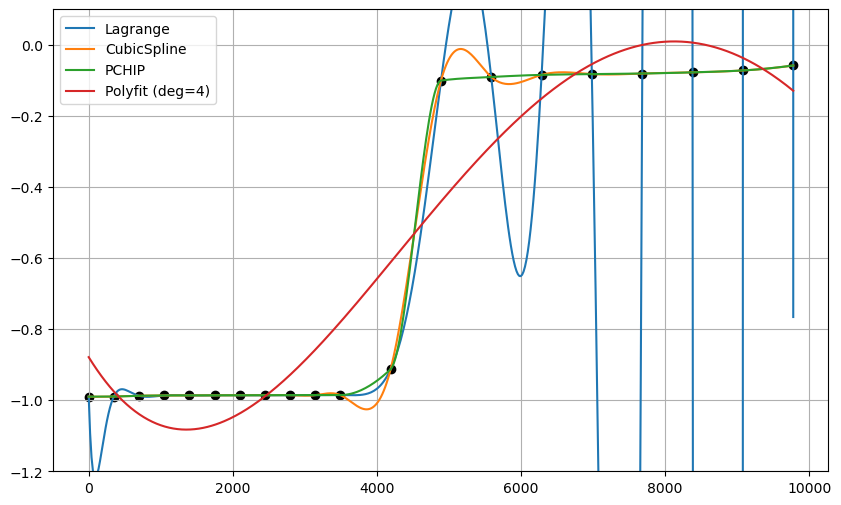

In [3]:
def get_lagrange(x, y, x_grid):
    poly = lagrange(x, y)
    return poly(x_grid)

def get_cubic_spline(x, y, x_grid):
    cs = CubicSpline(x, y)
    return cs(x_grid)

def get_pchip(x, y, x_grid):
    pchip = PchipInterpolator(x, y)
    return pchip(x_grid)

def get_poly_approx(x, y, x_grid, degree=5):
    coeffs = np.polyfit(x, y, degree)
    return np.polyval(coeffs, x_grid)

x_fine = np.linspace(x1.min(), x1.max(), 500)

plt.figure(figsize=(10, 6))
plt.scatter(x1, y1, color='black')

plt.plot(x_fine, get_lagrange(x1, y1, x_fine), label='Lagrange')
plt.plot(x_fine, get_cubic_spline(x1, y1, x_fine), label='CubicSpline')
plt.plot(x_fine, get_pchip(x1, y1, x_fine), label='PCHIP')
plt.plot(x_fine, get_poly_approx(x1, y1, x_fine, degree=4), label='Polyfit (deg=4)')

plt.ylim(-1.2, 0.1)
plt.legend()
plt.grid(True)
plt.show()

## Задача 2. Интерполяция полиномом Лагранжа.

Допишите класс, который конструирует интерполяционный полином Лагранжа, проходящий через точки, заданные как `xk` и `yk`.

In [4]:
class LagrangeInterpolator:
    def __init__(self, xk, yk):
        self.xk = np.asarray(xk, dtype=float)
        self.yk = np.asarray(yk, dtype=float)

    def __call__(self, x):
        n = len(self.xk)
        result = 0.0
        for i in range(n):
            basis = 1.0
            for j in range(n):
                if i != j:
                    basis *= (x - self.xk[j]) / (self.xk[i] - self.xk[j])
            result += self.yk[i] * basis
        return result

In [14]:
def runge_func(x, a=25):
    return 1.0 / (1.0 + a*x**2)

xx = np.linspace(-2, 2, 21)
yy = runge_func(xx)

lagr = LagrangeInterpolator(xx, yy)

assert_allclose(yy,
                [lagr(xval) for xval in xx],
                atol=1e-14)
print("end")


end


## Задача 3. Феномен Рунге

Рассмотрим функцию Рунге, $y=1/(1+25x^2)$. Интерполируйте эту функцию на интервале $x \in [-2, 2]$, используя полином Лагранжа с $m=3, 5, 7, 11$. Используйте равномерную сетку. Нарисуйте результат интерполяции вместе с исходной функцией на одном графике.

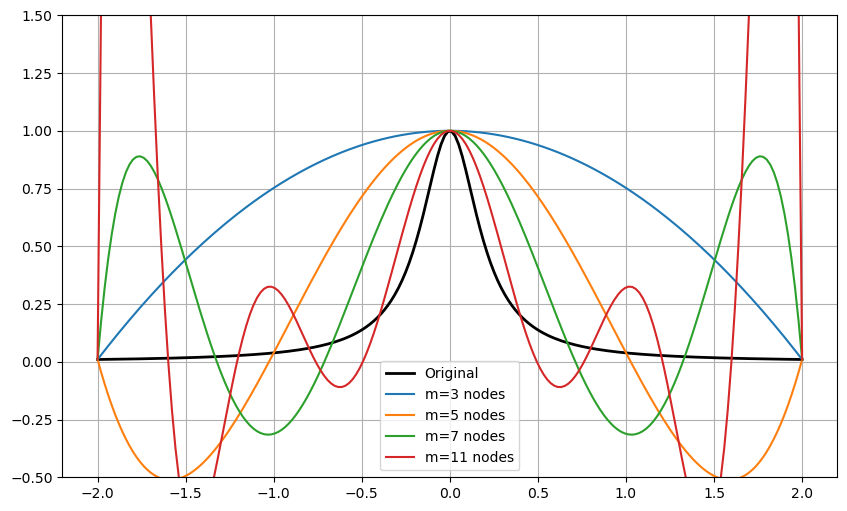

In [22]:
x_fine = np.linspace(-2, 2, 200)
y_true = runge_func(x_fine)

plt.figure(figsize=(10, 6))
plt.plot(x_fine, y_true, 'k', label='Original', lw=2)

for m in [3, 5, 7, 11]:
    xk = np.linspace(-2, 2, m)
    yk = runge_func(xk)
    lagr = LagrangeInterpolator(xk, yk)
    y_interp = [lagr(val) for val in x_fine]
    plt.plot(x_fine, y_interp, label=f'm={m} nodes')

plt.ylim(-0.5, 1.5)
plt.legend()
plt.grid(True)
plt.show()


Допишите функцию, которая возвращает узлы Чебышева.

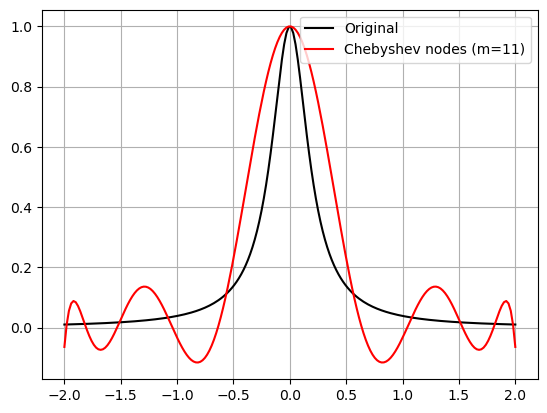

In [24]:
def cheb_nodes(n, a=-1, b=1):
    k = np.arange(n)
    nodes = np.cos((2 * (n - 1 - k) + 1) / (2 * n) * np.pi)
    return 0.5 * (a + b) + 0.5 * (b - a) * nodes

nodes_11 = cheb_nodes(11, -2, 2)
lagr_cheb = LagrangeInterpolator(nodes_11, runge_func(nodes_11))
y_cheb = [lagr_cheb(val) for val in x_fine]

plt.plot(x_fine, y_true, 'k', label='Original')
plt.plot(x_fine, y_cheb, 'r', label='Chebyshev nodes (m=11)')
plt.grid(True)
plt.legend()
plt.show()

In [25]:
nodes_11 = cheb_nodes(11)
nodes_11 = np.asarray(nodes_11)
assert (nodes_11[1:] > nodes_11[:-1]).all()

nodes, weights = roots_chebyt(5)
assert_allclose(cheb_nodes(5),
                nodes, atol=1e-14)

assert_allclose(cheb_nodes(5, a=-1, b=3),
                nodes*2 + 1, atol=1e-14)

Повторите интерполяцию Лагранжа функции Рунге с помощью узлов Чебышева. Постройте интерполянты. Также постройте интерполяцию кубическим сплайном тех же данных (`scipy.interpolate.CubicSpline`). Сравните величину явления Рунге для равномерной сетки и сетки Чебышева. Демонстрирует ли интерполяция сплайнами феномен Рунге?

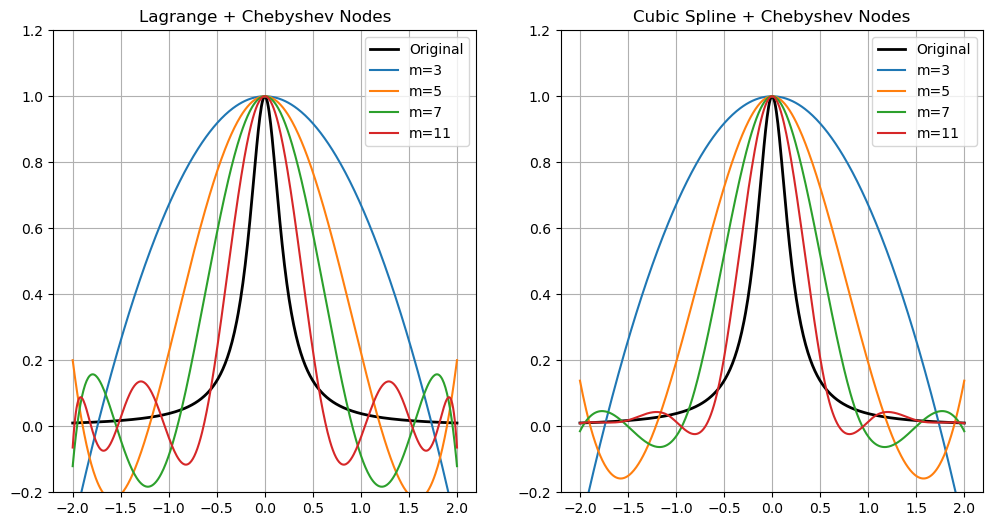

In [27]:
x_fine = np.linspace(-2, 2, 500)
y_true = runge_func(x_fine)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].plot(x_fine, y_true, 'k', lw=2, label='Original')
for m in [3, 5, 7, 11]:
    xk = cheb_nodes(m, a=-2, b=2)
    yk = runge_func(xk)
    lagr = LagrangeInterpolator(xk, yk)
    y_interp = [lagr(x) for x in x_fine]
    axes[0].plot(x_fine, y_interp, label=f'm={m}')

axes[0].set_title("Lagrange + Chebyshev Nodes")
axes[0].set_ylim(-0.2, 1.2)
axes[0].legend()
axes[0].grid(True)


axes[1].plot(x_fine, y_true, 'k', lw=2, label='Original')
for m in [3, 5, 7, 11]:
    xk = cheb_nodes(m, a=-2, b=2)
    yk = runge_func(xk)
    cs = CubicSpline(xk, yk)
    axes[1].plot(x_fine, cs(x_fine), label=f'm={m}')

axes[1].set_title("Cubic Spline + Chebyshev Nodes")
axes[1].set_ylim(-0.2, 1.2)
axes[1].legend()
axes[1].grid(True)

plt.show()

Другим известным трудным тестом для интерполяции является следующая периодическая функция:

$u(x)=\frac{\sqrt{\epsilon(2+\epsilon)}}{2\pi(1+\epsilon-\cos x)}, \quad -\pi \le x \le \pi, \quad \epsilon=0.21$

Проведите аналогичные вычисления и постройте графики для неё.

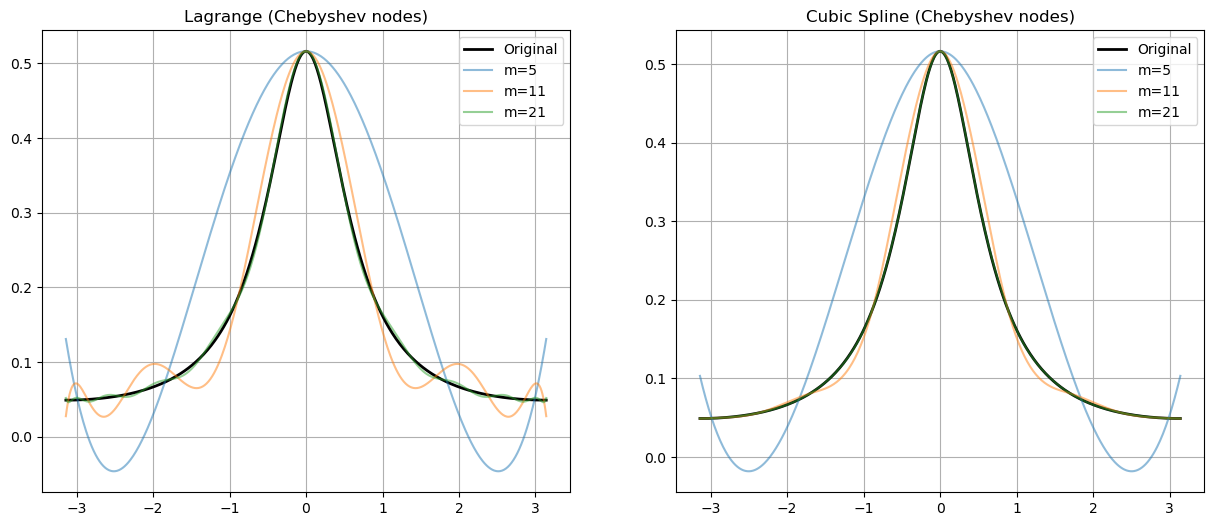

In [30]:
def periodic_test_func(x, eps=0.21):
    coeff = np.sqrt(eps * (2 + eps))
    return coeff / (2 * np.pi * (1 + eps - np.cos(x)))

a, b = -np.pi, np.pi
x_fine = np.linspace(a, b, 500)
y_true = periodic_test_func(x_fine)

def plot_interpolation_comparison(target_func, m_values):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    axes[0].plot(x_fine, y_true, 'k', lw=2, label='Original')
    for m in m_values:
        xk = cheb_nodes(m, a=a, b=b)
        yk = target_func(xk)
        lagr = LagrangeInterpolator(xk, yk)
        y_interp = [lagr(x) for x in x_fine]
        axes[0].plot(x_fine, y_interp, label=f'm={m}', alpha=0.5)

    axes[0].set_title("Lagrange (Chebyshev nodes)")
    axes[0].legend()
    axes[0].grid(True)


    axes[1].plot(x_fine, y_true, 'k', lw=2,label='Original')
    for m in m_values:
        xk = cheb_nodes(m, a=a, b=b)
        yk = target_func(xk)
        cs = CubicSpline(xk, yk)
        axes[1].plot(x_fine, cs(x_fine), label=f'm={m}', alpha=0.5)

    axes[1].set_title("Cubic Spline (Chebyshev nodes)")
    axes[1].legend()
    axes[1].grid(True)

    plt.show()

plot_interpolation_comparison(periodic_test_func, [5, 11, 21])

## Задача 4. UnivariateSpline.

Прочитать документацию к UnivariateSpline и определить оптимальное значение для параметра сглаживания **s**, учитывая, что шум был задан в виде $u_i = \dots + 0.5\xi_i, \xi_i \sim \mathcal{N}(0, 1)$. Экспериментально проверить оптимальность этого значения для какой-либо функции

MSE (s=0): 0.2620
MSE (s=25.0): 0.0423
MSE (s=1000): 1.2915


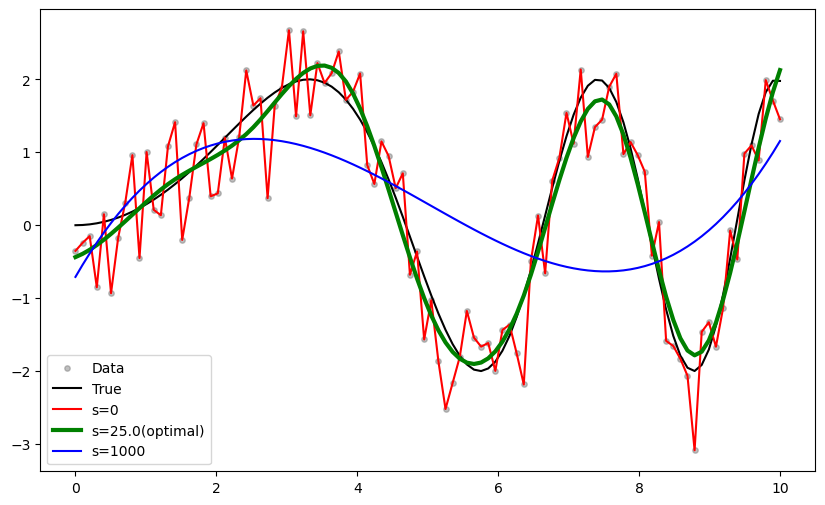

In [8]:
np.random.seed(1337)
n = 100
sigma = 0.5
s_opt = n * (sigma**2)

x = np.linspace(0, 10, n)
y_true = 2*np.sin(x**2/7)
y_noisy = y_true + sigma * np.random.randn(n)

spl_0 = UnivariateSpline(x, y_noisy, s=0)
spl_opt = UnivariateSpline(x, y_noisy, s=s_opt)
spl_big = UnivariateSpline(x, y_noisy, s=1e3)

print(f"MSE (s=0): {mean_squared_error(y_true, spl_0(x)):.4f}")
print(f"MSE (s={s_opt}): {mean_squared_error(y_true, spl_opt(x)):.4f}")
print(f"MSE (s=1000): {mean_squared_error(y_true, spl_big(x)):.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(x, y_noisy, color='gray', alpha=0.5, s=15, label='Data')
plt.plot(x, y_true, 'k', label='True')
plt.plot(x, spl_0(x), 'r', label='s=0')
plt.plot(x, spl_opt(x), 'g', lw=3, label=f's={s_opt}(optimal)')
plt.plot(x, spl_big(x), 'b', label='s=1000')
plt.legend()
plt.show()

## Задача 5. Производная и шум

Цель - найти производную следующей таблично-заданной функции с шумом. Всего есть 1000 узлов. Генерировать новые точки нельзя.

$$u(t) = \frac{200}{1 + \frac{t}{200}} (0.5 + 0.5 \cdot \cos(0.04 \cdot t)) + \text{noise}$$

1. Сделайте это через конечные разности, используя минимальное даное расстояние между точками. Вспоминаем семинар 1.
2. Сделайте это через оптимальный шаг численного дифференциирования. То есть, при оценке производной надо брать несоседние точки исходя из погрешностей $u_i$. Какой шаг надо брать по индексам точек?
3. Сделайте это через `UnivariateSpline`, используя метод `.derivative()` - он аналитически дифференциирует объект сплайна и выдаёт также объект сплайна (т.е. можем обращаться к нему как к функции). Не забывайте корректно определить параметр **s**.

Сравните все 3 способа численного взятия производной с аналитической производной как графически, так и используя какой-нибудь Loss.

In [ ]:
t = np.linspace(0, 1000, 1000)
u = 200 / (1 + t/200) * (0.5 + 0.5 * np.cos(0.04 * t)) + 0.5 * np.random.randn(len(t))

In [12]:
def get_u_true_der(t):
    # Аналитическая производная u(t)
    term1 = -40000 / (200 + t)**2 * (0.5 + 0.5 * np.cos(0.04 * t))
    term2 = 40000 / (200 + t) * (-0.5 * 0.04 * np.sin(0.04 * t))
    return term1 + term2

def finite_diff(t, u, k=1):
    dt = t[k] - t[0]
    der = (u[2*k:] - u[:-2*k]) / (2 * dt)
    return t[k:-k], der


np.random.seed(1337)
t = np.linspace(0, 1000, 1000)
dt = t[1] - t[0]
u_clean = 200 / (1 + t/200) * (0.5 + 0.5 * np.cos(0.04 * t))
u_noisy = u_clean + 0.5 * np.random.randn(len(t))
u_der_true = get_u_true_der(t)

# 1. Минимальный шаг (k=1)
t1, der1 = finite_diff(t, u_noisy, k=1)

# 2. Оптимальный шаг
# h_opt ~ (3 * sigma / M3)**(1/3).
k_opt = 5
t2, der2 = finite_diff(t, u_noisy, k=k_opt)

# 3. Сплайн с s = n * sigma^2
s_val = len(t) * (0.5**2)
spl = UnivariateSpline(t, u_noisy, s=s_val)
der3_func = spl.derivative()
der3 = der3_func(t)

mask = (t >= t2[0]) & (t <= t2[-1])
t_comp = t[mask]

loss1 = np.sqrt(mean_squared_error(get_u_true_der(t1), der1))
loss2 = np.sqrt(mean_squared_error(get_u_true_der(t2), der2))
loss3 = np.sqrt(mean_squared_error(u_der_true, der3))

print(f"RMSE (Min step FD): {loss1:.4f}")
print(f"RMSE (Opt step FD): {loss2:.4f}")
print(f"RMSE (Spline der):  {loss3:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(t, u_der_true, 'k', lw=3, label='Analytical')
plt.plot(t1, der1, 'r', alpha=0.3, label='FD Min step (k=1)')
plt.plot(t2, der2, 'g', lw=2, label=f'FD Opt step (k={k_opt})')
plt.plot(t, der3, 'b', lw=2, label='Spline Derivative')
plt.legend()
plt.grid(True)
plt.show()


RMSE (Min step FD): 0.3452
RMSE (Opt step FD): 0.0693
RMSE (Spline der):  0.0183


<IPython.core.display.Javascript object>